In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)



In [40]:
df = pd.read_csv("bank_notes - bank_notes.csv")

In [41]:
print("First five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
print(df.describe())


First five rows:
   variance  skewness  curtosis  entropy  Target
0   3.62160    8.6661   -2.8073 -0.44699       0
1   4.54590    8.1674   -2.4586 -1.46210       0
2   3.86600   -2.6383    1.9242  0.10645       0
3   3.45660    9.5228   -4.0112 -3.59440       0
4   0.32924   -4.4552    4.5718 -0.98880       0

Last five rows:
      variance  skewness  curtosis  entropy  Target
1367   0.40614   1.34920   -1.4501 -0.55949       1
1368  -1.38870  -4.87730    6.4774  0.34179       1
1369  -3.75030 -13.45860   17.5932 -2.77710       1
1370  -3.56370  -8.38270   12.3930 -1.28230       1
1371  -2.54190  -0.65804    2.6842  1.19520       1

Dataset shape:
(1372, 5)

Column names:
['variance', 'skewness', 'curtosis', 'entropy', 'Target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1

In [42]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())



Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
Target      0
dtype: int64

Duplicate rows:
24



Target class distribution:
Target
0    762
1    610
Name: count, dtype: int64


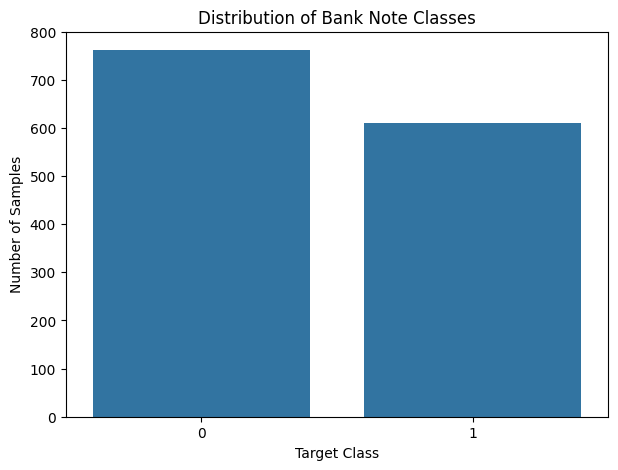

In [43]:
print("\nTarget class distribution:")
print(df["Target"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Target")
plt.title("Distribution of Bank Note Classes")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.show()

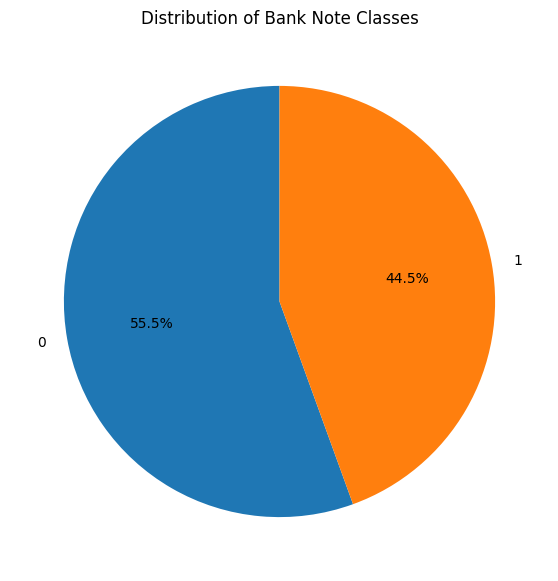

In [44]:
class_counts = df["Target"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribution of Bank Note Classes")
plt.show()

In [46]:
numerical_features = [
    "variance", "skewness", "curtosis", "entropy"
]

print("\nNumerical features:")
print(numerical_features)


Numerical features:
['variance', 'skewness', 'curtosis', 'entropy']


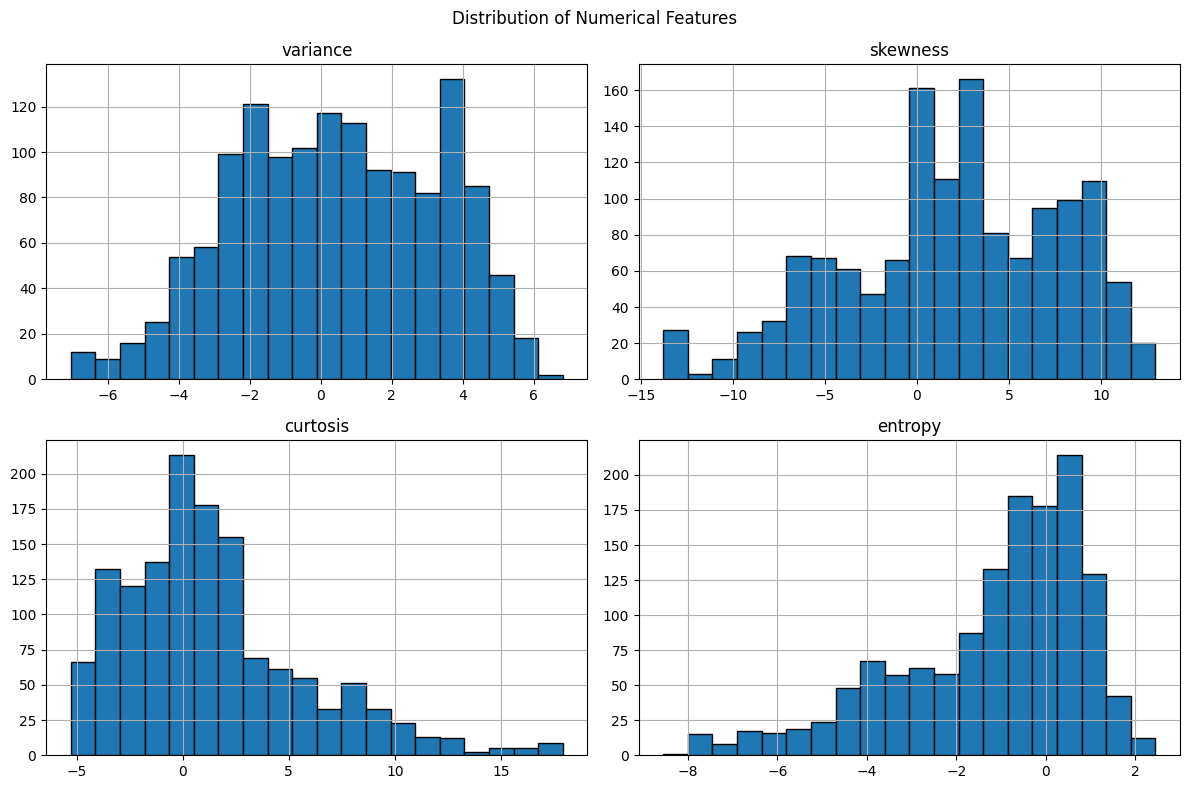

In [47]:
df[numerical_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [49]:
model = GaussianNB()
model.fit(X_train, y_train)

GaussianNB()

In [50]:
y_pred = model.predict(X_test)

print("\nActual Labels:")
print(y_test.to_numpy()[:10])

print("\nPredicted Labels:")
print(y_pred[:10])



Actual Labels:
[0 0 0 1 0 1 0 1 1 1]

Predicted Labels:
[1 0 0 1 0 1 0 1 1 1]



Confusion Matrix:
[[62 28]
 [ 5 85]]


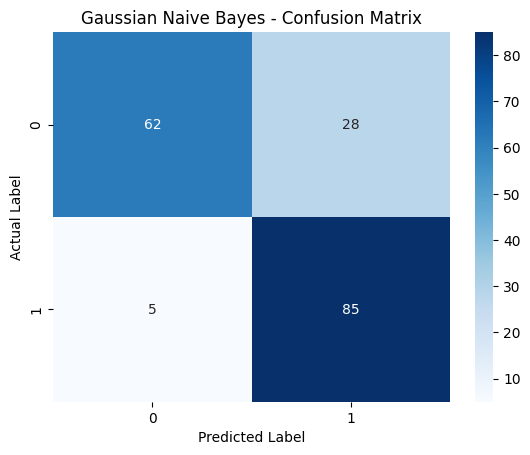

In [52]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [53]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print("\nModel Evaluation")
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Model Evaluation
Accuracy  : 0.8167 (81.67%)
Precision : 0.8388
Recall    : 0.8167
F1-score  : 0.8136

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.69      0.79        90
           1       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180

